In [8]:
%matplotlib inline
from nilearn import plotting
from nilearn.plotting.cm import _cmap_d as nilearn_cmaps

import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

In [3]:
chen = nib.load('results/chen_lesion.nii.gz')
qq = nib.load('results/qin_lesion.nii.gz')
template = nib.load('/data1/qinqian/MRI/data/Atlas/Regionalgrowth_and_atlas_Consistent_High_definition_Spatio-tempora/NeonatalAtlas2/template_T2_17.nii.gz')

In [4]:
import pandas as pd

In [9]:
dice = pd.read_csv('results/dice_coef.xls')
dice.iloc[:, 4:].mean(axis=0)

1      0.743930
4      0.369858
6      0.029126
all    0.841064
dtype: float64

0.23784086284086284

findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.
findfont: Font family ['normal'] not found. Falling back to DejaVu Sans.


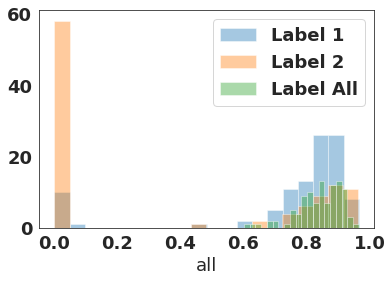

In [10]:
import seaborn as sns
sns.set_style('white')
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 18}
matplotlib.rc('font', **font)

x = dice.iloc[:, 4]
y = dice.iloc[:, 5]
z = dice.iloc[:, 7]
sns.distplot(x, label='Label 1',  kde=False, rug=False,bins=20)
sns.distplot(y, label= 'Label 2',  kde=False, rug=False, bins=20)
sns.distplot(z, label='Label All',  kde=False, rug=False, bins=20)
plt.legend();

np.sum(qq.get_data()>0.1)/np.sum(qq.get_data()>0)

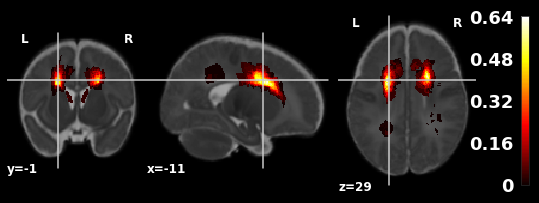

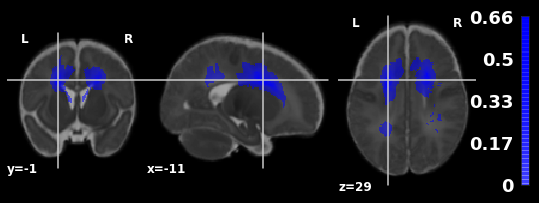

In [13]:
def blue_r():
    cdict = {'red':  ((0.0, 0.0, 0.0),
                      (1.0, 0.0, 0.0)),
             'green': ((0.0, 0.0, 0.0),
                       (1.0, 0.0, 0.0)),
             'blue': ((0.0, 0.0, 1.0),
                      (1.0, 0.3, 1.0))}
    return  LinearSegmentedColormap('Blue_r', cdict)

plotting.plot_stat_map(qq, bg_img=template)
plotting.plot_stat_map(chen, bg_img=template, cmap=nilearn_cmaps['blue_transparent_full_alpha_range'])
plt.savefig('results/Fig4.pdf')